# Audio Pipeline and Voiceprint Model

**Role C: audio lead.** This notebook walks through the audio part of the system: loading the voice recordings, plotting and interpreting them, augmenting them, extracting features into `audio_features.csv`, and training the voiceprint verification model.

All logic lives in `src/audio_processing.py` and `src/train_voice_model.py`; the notebook calls those scripts so the notebook and the command-line app always agree.

Run it locally from the repository (`pip install -r requirements.txt` first).

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

import audio_processing as ap
import train_voice_model as tv

## 1. Recordings

Each member recorded the two phrases **"Yes, approve"** and **"Confirm transaction"** on a phone (`.m4a`, 48 kHz). One extra recording from a person outside the team (`Diff.m4a`) is the unauthorized sample.

Every recording is converted to the same format before anything else:

- resampled to **16 kHz mono** (speech carries very little information above 8 kHz),
- **silence trimmed** from both ends (anything 30 dB below the peak),
- **peak-normalised**, so loudness differences between phones do not leak into the features,
- saved as `media/audio/original/<member>_<phrase>_<take>.wav` (non-members go to `media/audio/unauthorized/`).

In [2]:
manifest = ap.convert_raw_recordings()
manifest

,raw_file,member,phrase,wav,seconds
0,Diff.m4a,unknown,diff,media/audio/unauthorized/unknown_diff.wav,1.95
1,Nick-approve.m4a,nick,yes_approve,media/audio/original/nick_yes_approve_1.wav,1.73
2,Nick-transaction.m4a,nick,confirm_transaction,media/audio/original/nick_confirm_transaction_...,1.76
3,Placide_Confirm.m4a,placide,confirm_transaction,media/audio/original/placide_confirm_transacti...,1.60
4,Placide_Yes_approve.m4a,placide,yes_approve,media/audio/original/placide_yes_approve_1.wav,1.50
5,denyse_Confirm.m4a,denyse,confirm_transaction,media/audio/original/denyse_confirm_transactio...,1.70
6,denyse_Yes_approve.m4a,denyse,yes_approve,media/audio/original/denyse_yes_approve_1.wav,2.30


## 2. Waveforms and spectrograms

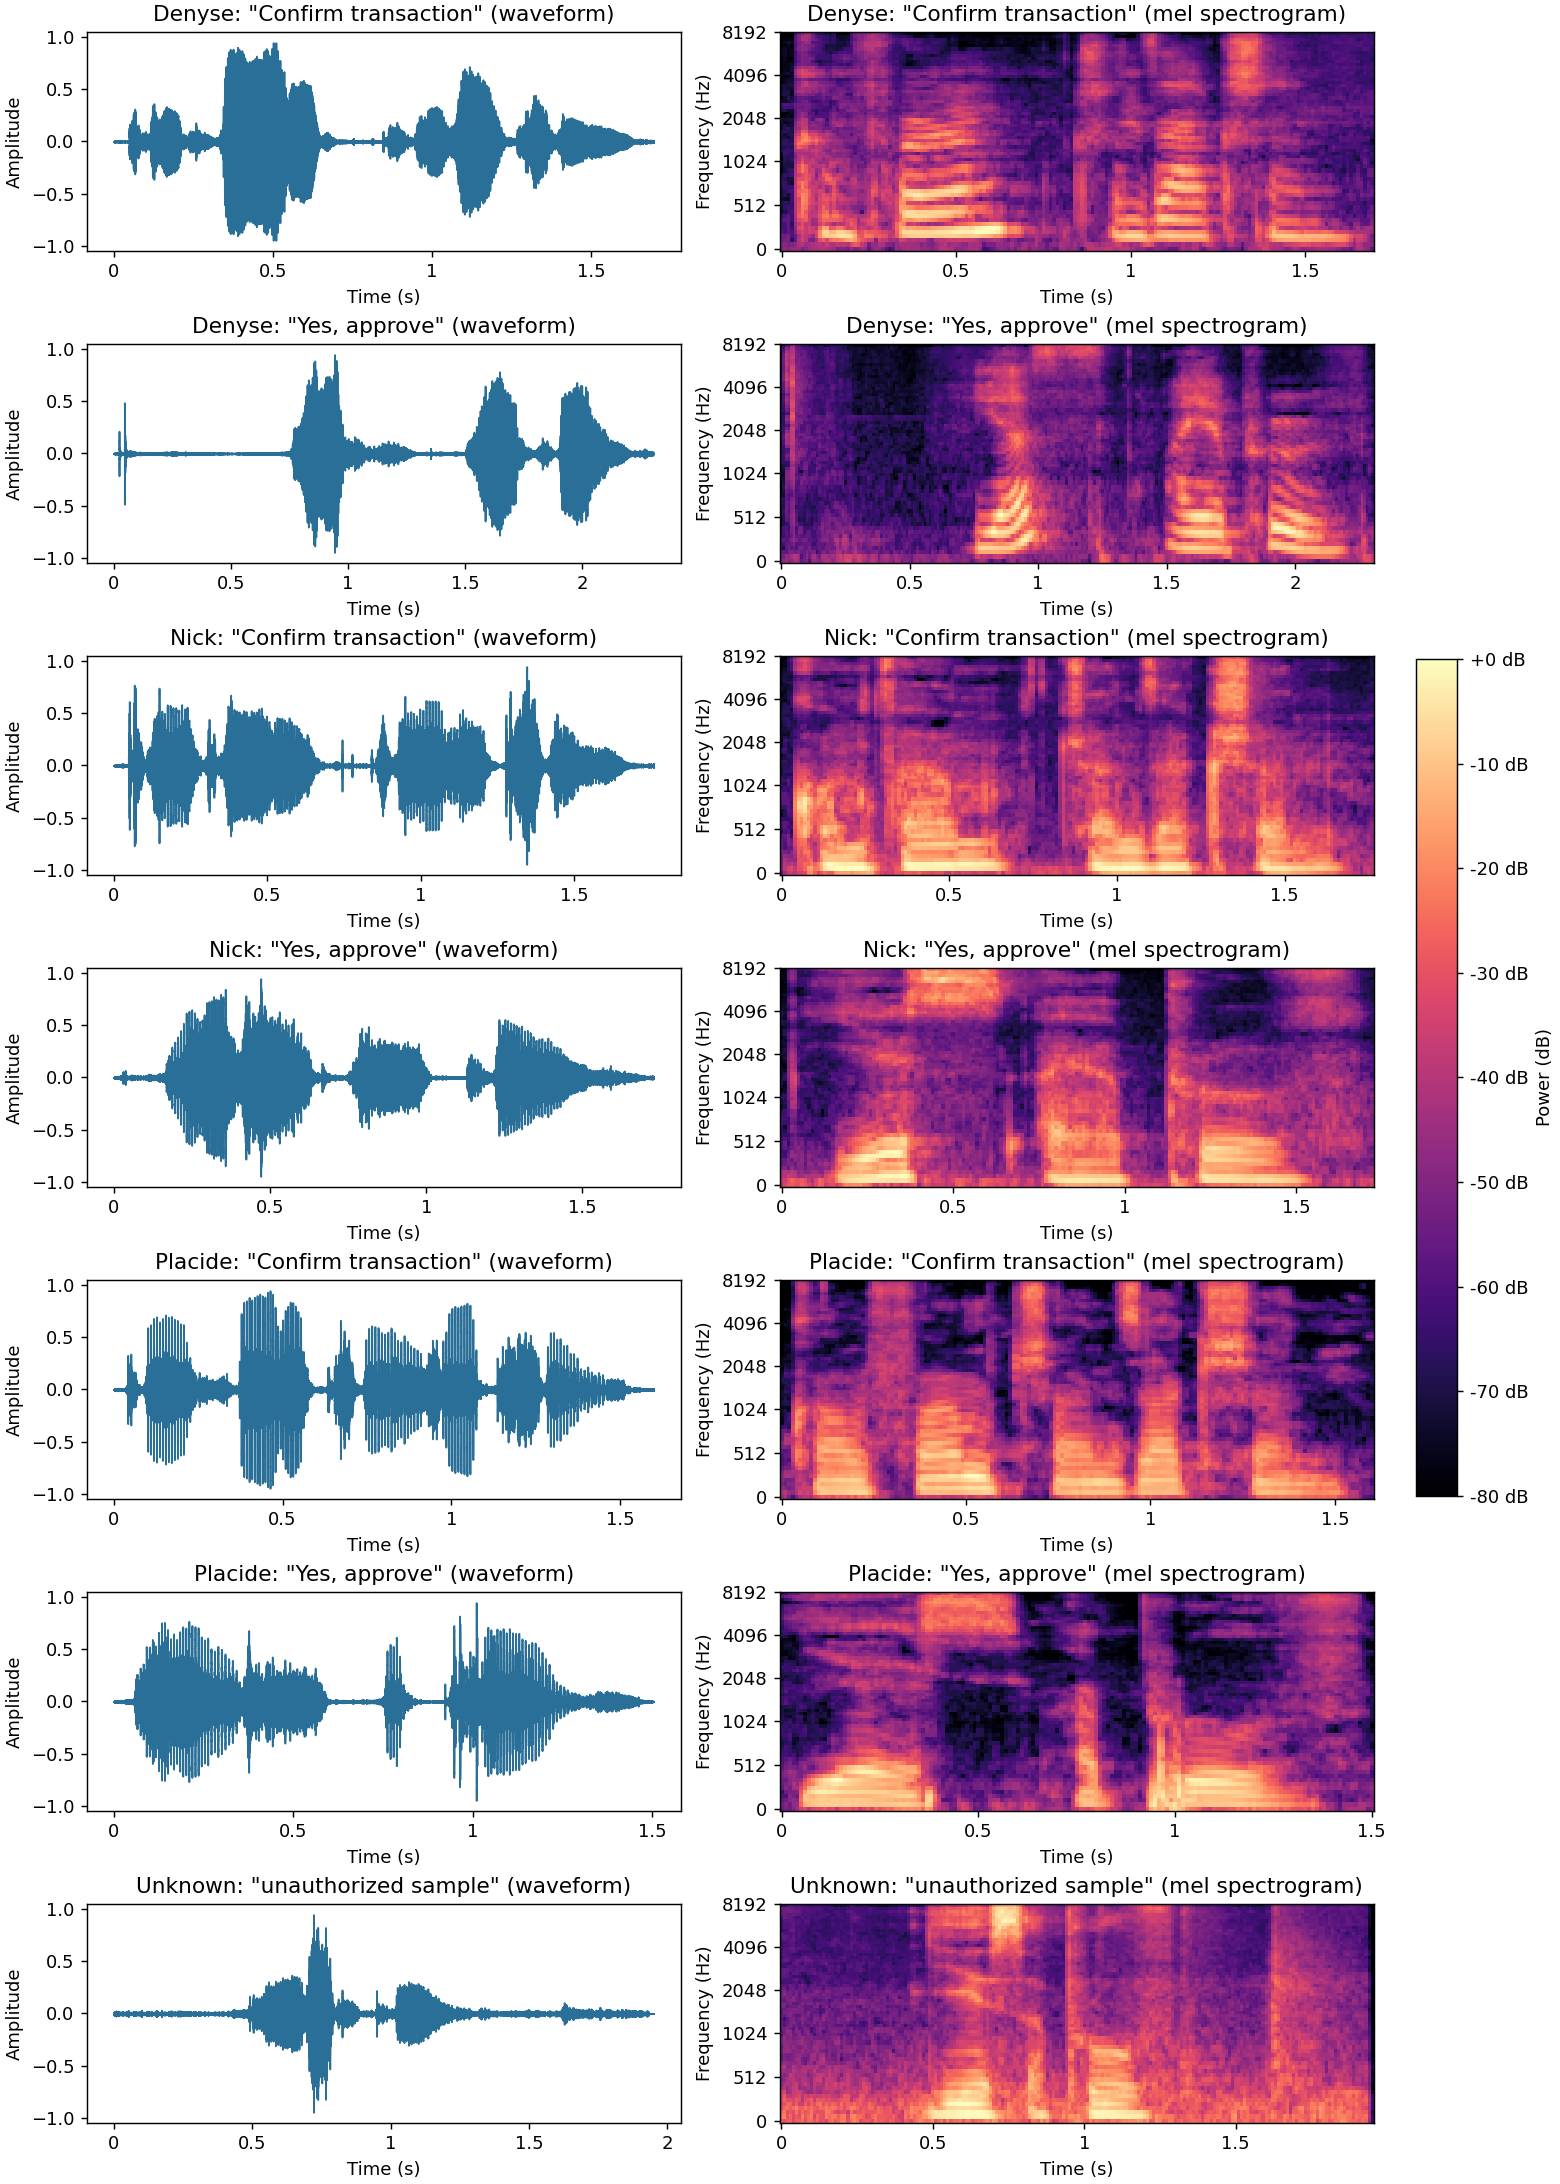

In [3]:
display(Image(ap.plot_waveforms_and_spectrograms()))

**Interpretation**

- **Waveforms (left).** Each burst is a syllable. "Confirm transaction" (5 syllables) shows more bursts than "Yes, approve" (3), and the gaps between words drop to almost zero amplitude, which means the member recordings have very little background noise. After trimming, every clip is 1.5 to 2.3 s long.
- **Spectrograms (right).** The horizontal stripes are the harmonics of the speaker's pitch, visible during vowels. Denyse's stripes are widely spaced (average pitch about 195 to 205 Hz) while Nick's and Placide's are tightly packed (about 105 to 110 Hz). The bright columns that reach up to 8 kHz are the hissing consonants ("s" in *yes*, "s" and "sh" in *transaction*). Most of the energy sits below 1 kHz.
- **Quality issues found.** (1) Denyse's "Yes, approve" starts with a click followed by about 0.7 s of silence; the click is loud, so the trimmer keeps it. (2) The unauthorized clip has a visible noise floor (the spectrogram is never dark) and much quieter speech. To stop pauses and noise from distorting the features, feature statistics are computed over **voiced frames only** (section 4).
- **Consequence for the model.** Pitch alone separates Denyse from the others, but Nick, Placide and the unauthorized speaker all have a similar pitch, so the model must rely on the spectral shape (MFCCs) to tell them apart.

## 3. Augmentation

Each clip gets six augmented copies (three techniques, two settings each), saved in `media/audio/augmented/`:

| Augmentation | Setting | Simulates |
|---|---|---|
| Pitch shift | +1 / -1 semitone | natural day-to-day variation in a voice |
| Time stretch | 15% faster / 15% slower | speaking faster or slower |
| Background noise | white noise at 20 dB / 10 dB SNR | a quiet room / a noisy room |

The pitch shift is kept small on purpose: a large shift would turn one speaker's voice into something closer to another person's, which is the opposite of what a voiceprint model should learn.

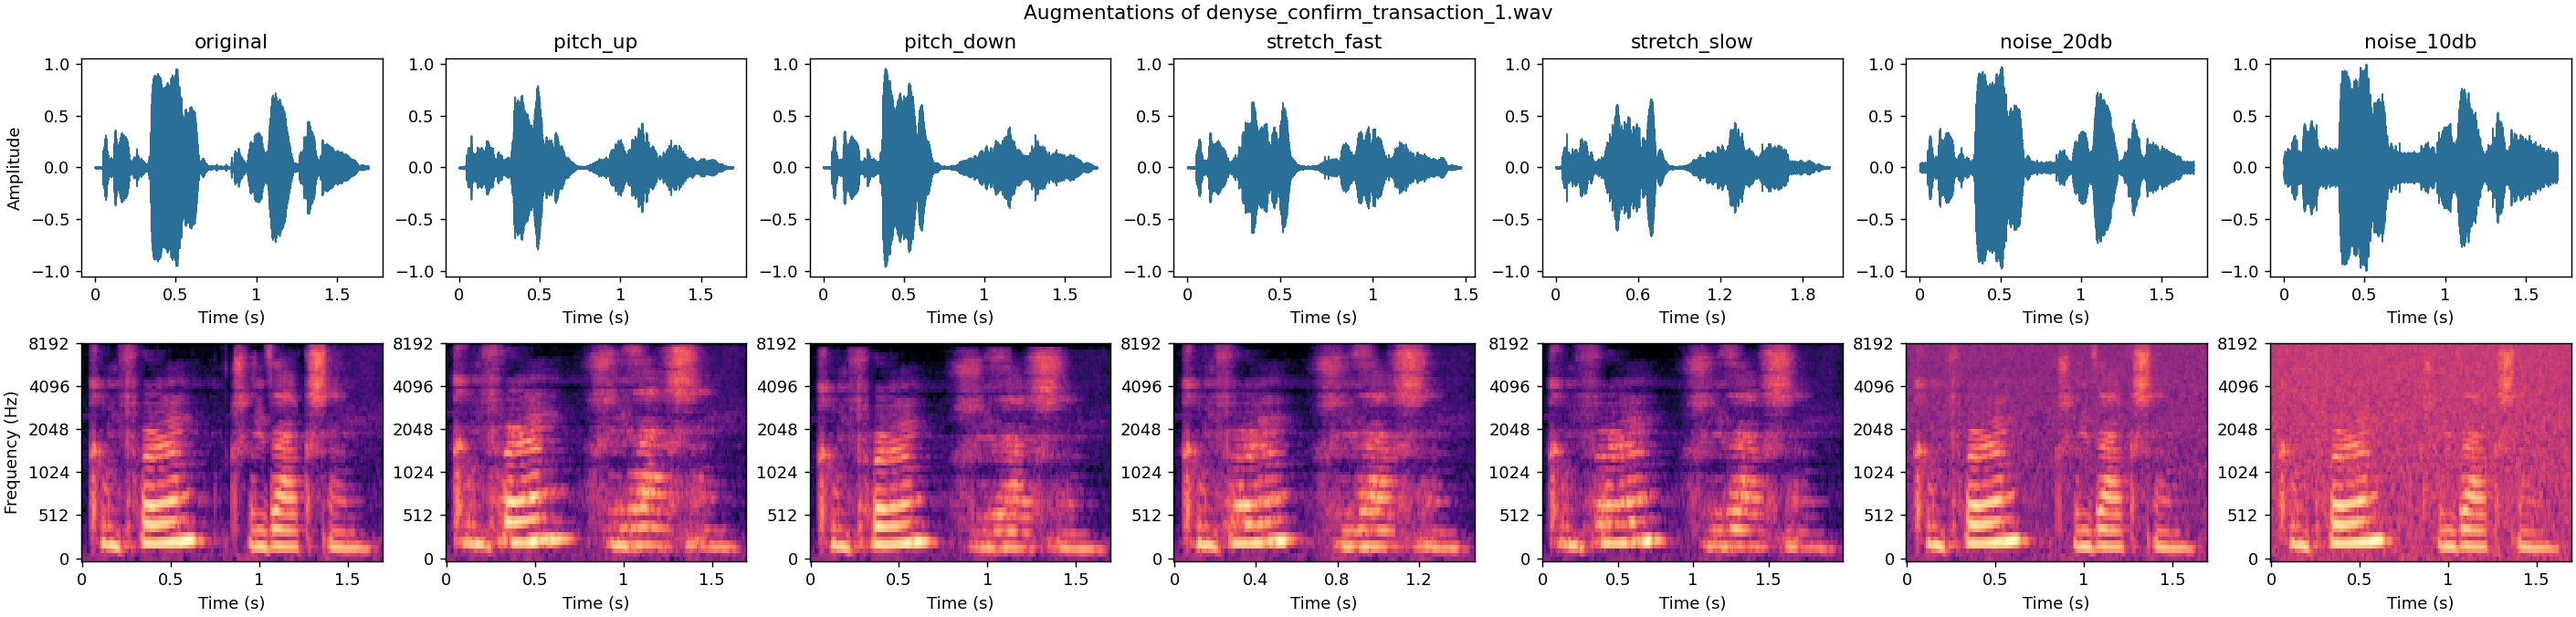

In [4]:
display(Image(ap.plot_augmentations()))

**Interpretation.** Pitch shifting moves the harmonic stripes up or down without changing the duration. Time stretching changes the duration (1.47 s and 2.00 s against the original 1.70 s) without moving the stripes. Noise fills the dark (silent) regions of the spectrogram; at 10 dB the weaker high-frequency consonants are almost buried, which is why this is the hardest augmentation for the model.

## 4. Feature extraction → `audio_features.csv`

Frame-level features are computed every 10 ms and summarised per clip by their mean and standard deviation over the voiced frames:

| Feature group | Columns | What it captures |
|---|---|---|
| MFCCs (13) | `mfcc_i_mean`, `mfcc_i_std` | shape of the vocal tract (the core voiceprint feature) |
| Delta MFCCs (13) | `delta_mfcc_i_std` | how fast the spectrum changes |
| Spectral roll-off, centroid, bandwidth | `*_mean`, `*_std` | brightness of the voice |
| RMS energy | `rms_energy_mean`, `rms_energy_std` | loudness and its variation |
| Zero-crossing rate | `zcr_mean`, `zcr_std` | noisiness |
| Pitch | `f0_mean`, `f0_std`, `voiced_fraction` | how high the voice is |
| Duration | `duration_s` | clip length |

In [5]:
features = ap.build_feature_table()
features.to_csv(ap.FEATURES_PATH, index=False)
print("shape:", features.shape, "| missing values:", int(features.isna().sum().sum()))
print(features.groupby("member")["augmentation"].count().rename("clips"))
features[features["is_original"] == 1][
    ["member", "phrase", "duration_s", "f0_mean", "voiced_fraction", "rolloff_mean", "rms_energy_mean", "mfcc_1_mean"]
].round(2)

shape: (49, 59) | missing values: 0
member
denyse     14
nick       14
placide    14
unknown     7
Name: clips, dtype: int64


,member,phrase,duration_s,f0_mean,voiced_fraction,rolloff_mean,rms_energy_mean,mfcc_1_mean
0,denyse,confirm_transaction,1.70,206.16,0.69,2606.84,0.16,105.67
7,denyse,yes_approve,2.30,193.96,0.40,2979.17,0.16,101.13
14,nick,confirm_transaction,1.76,109.18,0.63,1679.90,0.18,141.54
21,nick,yes_approve,1.73,104.30,0.55,2765.30,0.15,121.56
28,placide,confirm_transaction,1.60,111.49,0.69,1947.64,0.16,146.85
35,placide,yes_approve,1.50,108.18,0.46,3014.04,0.18,104.31
42,unknown,unauthorized,1.95,101.26,0.42,4222.94,0.06,94.70


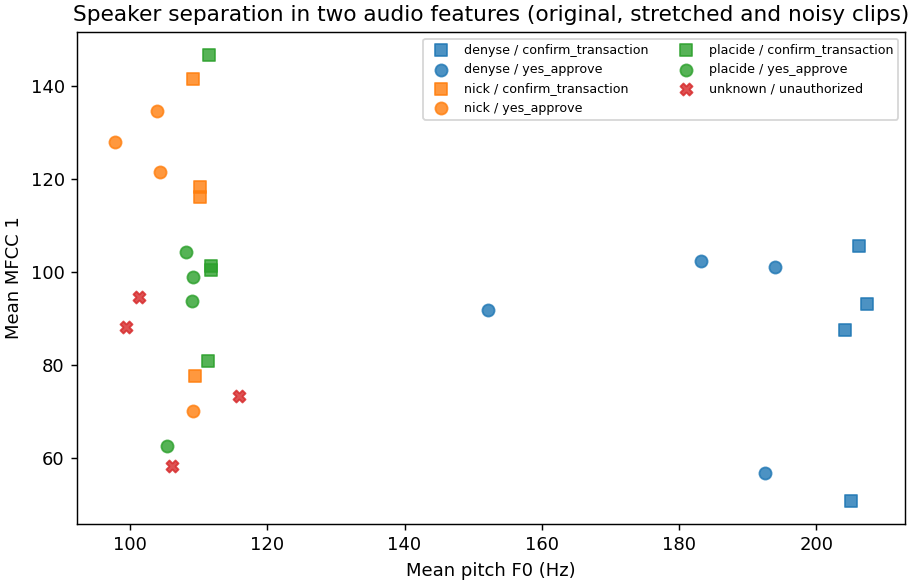

In [6]:
display(Image(ap.plot_feature_separation(features)))

**Interpretation.** The table confirms what the spectrograms showed: Denyse's mean pitch is about twice that of Nick and Placide, and the unauthorized clip stands out through its low energy and high roll-off (its background noise). In the scatter plot Denyse forms her own cluster on the right, while Nick, Placide and the unauthorized speaker overlap on the left. These are the hard cases for the model.

## 5. Voiceprint verification model

**Task.** Identify which member is speaking. A voice is only *verified* when the model's confidence reaches a threshold; otherwise the result is `unknown` and access is denied.

**Evaluation: leave-one-recording-out.** A recording is held out together with all six of its augmented copies, so the model is always tested on a recording it has never heard in any form. Splitting the clips at random would put augmented copies of the same recording in both train and test and report near-perfect, meaningless scores.

**Feature sets compared.** *All features* against *long-term averages* (only the `*_mean` columns). Standard deviations, deltas and duration describe how one particular phrase unfolds rather than who is speaking.

**Threshold.** Chosen from the held-out predictions as the confidence that best separates correct identifications from wrong ones. The unauthorized clip is never used for training or for choosing the threshold; it is a separate test.

In [7]:
tv.main()

members: ['denyse', 'nick', 'placide'] | clips: 42 from 6 recordings | features: {'all features': 53, 'long-term averages': 19}



Leave-one-recording-out CV:
                      model           features  accuracy  f1_macro  log_loss  selected
    Baseline (class priors)       all features     0.000     0.000     1.609     False
Logistic Regression (C=0.1)       all features     0.452     0.461     1.073     False
              Random Forest       all features     0.452     0.439     0.990     False
                  SVM (RBF)       all features     0.405     0.416     1.178     False
Logistic Regression (C=0.1) long-term averages     0.714     0.701     0.654      True
              Random Forest long-term averages     0.595     0.521     0.859     False
                  SVM (RBF) long-term averages     0.619     0.585     0.801     False

Selected: Logistic Regression (C=0.1) on long-term averages | confidence threshold: 0.631
  unseen member recordings verified correctly: 52%
  unseen member recordings rejected:           48%
  accepted under the wrong name:               0%
  enrolled (training) clips veri

**Interpretation**

- **Long-term averages win for every model** (accuracy 0.60 to 0.71 against 0.40 to 0.45 with all features; chance is 0.33). The selected model is Logistic Regression on the 19 averaged features: accuracy 0.71, macro-F1 0.70, log-loss 0.65.
- **This is a hard test and a small dataset.** Each member has one recording per phrase, so every fold asks the model to recognise a speaker saying a phrase it has never heard from them. Six recordings also means the scores are rough estimates. Denyse is identified in all 14 of her held-out clips; every error is a confusion between Nick and Placide, the two voices with similar pitch (Placide's "Confirm transaction" is attributed to Nick in all 7 clips).
- **The threshold makes the system cautious.** At 0.63, no held-out clip is accepted under the wrong name, at the cost of rejecting about half of the unseen member recordings. For an approval step, wrongly denying a member is the safer error.
- **Unauthorized test.** The non-member recording is rejected (confidence 0.53), as are 5 of its 6 augmented copies. This is one stranger, so it shows the mechanism works, not how often it would work.
- **How to improve it.** More data, not a different model: several takes of each phrase per member, and a few more non-member voices to test rejection properly. `audio_processing.py` picks up extra recordings automatically.

## 6. Interface for the CLI

`predict_voice(audio_path)` in `src/predict.py` returns `(member_name or "unknown", confidence)`. It accepts any audio file and runs the same cleaning and feature extraction as above.

In [8]:
from predict import predict_voice

for path in sorted((ROOT / "media" / "audio").glob("*.m4a")):
    name, conf = predict_voice(path)
    print(f"{path.name:26s} -> {name:8s} (confidence {conf:.2f})  {'VERIFIED' if name != 'unknown' else 'ACCESS DENIED'}")

Diff.m4a                   -> unknown  (confidence 0.53)  ACCESS DENIED
Nick-approve.m4a           -> nick     (confidence 0.90)  VERIFIED


Nick-transaction.m4a       -> nick     (confidence 0.90)  VERIFIED
Placide_Confirm.m4a        -> placide  (confidence 0.72)  VERIFIED
Placide_Yes_approve.m4a    -> placide  (confidence 0.89)  VERIFIED


denyse_Confirm.m4a         -> denyse   (confidence 0.92)  VERIFIED
denyse_Yes_approve.m4a     -> denyse   (confidence 0.95)  VERIFIED
